# Complete Airfare Price Estimation — Machine Learning Pipeline
**Author:** Senior Machine Learning Engineer  
**Objective:** End-to-end Airfare Price Prediction project utilizing regression algorithms, automated preprocessing pipelines, exploratory data analysis, hyperparameter tuning, model interpretation, model serialization (`airfare_model.pkl`), and integration with a FastAPI web service.

---

### Project Pipeline Workflow
1. **Dataset Access & Verification**: Programmatic inspection of 300,153 flight records.
2. **Exploratory Data Analysis (EDA)**: Statistical summaries and visualizations of fare dynamics.
3. **Data Preprocessing & Feature Engineering**: Scikit-Learn `ColumnTransformer` & `Pipeline` to prevent data leakage.
4. **Regression Algorithm Benchmark**: Comparing 9 models (Linear, Ridge, Lasso, ElasticNet, Decision Tree, Random Forest, Extra Trees, Gradient Boosting, HistGradientBoosting).
5. **Model Selection Analysis**: In-depth trade-off evaluation (MAE, RMSE, R², training latency, generalization).
6. **Hyperparameter Tuning**: Regularized parameter optimization for enterprise stability.
7. **Production Model Training & Export**: Serialization of full fitted pipeline (`airfare_model.pkl`) and metrics (`model_metrics.json`).
8. **Independent Inference Verification**: Validating pipeline reloading and handling unseen categories.


## 1. Environment Setup and Library Imports
We import standard data science and machine learning libraries:
- `pandas` & `numpy` for data manipulation.
- `matplotlib` & `seaborn` for publication-quality visualizations.
- `scikit-learn` for preprocessing, pipeline construction, regression estimators, and evaluation metrics.
- `joblib` & `json` for model serialization and metadata tracking.


In [1]:
import os
import time
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-Learn Preprocessing & Pipeline
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Regression Algorithms
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    GradientBoostingRegressor,
    HistGradientBoostingRegressor
)

# Evaluation Metrics
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11

print("All required libraries imported successfully!")


Matplotlib is building the font cache; this may take a moment.


All required libraries imported successfully!


## 2. Dataset Access and Verification (Part 1)
We access the dataset `Cleaned_Airfare_Dataset_With_Dates.csv` programmatically from the project directory.
In accordance with production best practices:
- We read the CSV directly without truncating or substituting with small synthetic samples.
- We print only structural summaries, schema types, missing values, and statistical properties.
- We verify all 300,153 records and 16 columns.


In [2]:
dataset_path = "Cleaned_Airfare_Dataset_With_Dates.csv"
assert os.path.exists(dataset_path), f"Dataset file not found at {dataset_path}"

# Load full dataset into pandas
df = pd.read_csv(dataset_path)

print(f"Dataset successfully loaded.")
print(f"Total Rows:    {df.shape[0]:,}")
print(f"Total Columns: {df.shape[1]}")


Dataset successfully loaded.
Total Rows:    300,153
Total Columns: 16


In [3]:
# Display schema information and datatypes
print("=== DATASET SCHEMA & DATA TYPES ===")
print(df.dtypes)
print("\n=== FIRST 3 RECORDS SAMPLE ===")
display(df.head(3))


=== DATASET SCHEMA & DATA TYPES ===
airline                 str
flight                  str
source_city             str
departure_time          str
stops                   str
arrival_time            str
destination_city        str
class                   str
duration            float64
days_left             int64
price                 int64
booking_date            str
journey_date            str
day_of_week             str
month                   str
route_distance      float64
dtype: object

=== FIRST 3 RECORDS SAMPLE ===


,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price,booking_date,journey_date,day_of_week,month,route_distance
0,SpiceJet,SG-8709,Delhi,Evening,zero,Night,Mumbai,Economy,2.17,1,5953,2026-11-14,2026-11-15,Sunday,November,1137.1
1,SpiceJet,SG-8157,Delhi,Early_Morning,zero,Morning,Mumbai,Economy,2.33,1,5953,2026-11-14,2026-11-15,Sunday,November,1137.1
2,AirAsia,I5-764,Delhi,Early_Morning,zero,Early_Morning,Mumbai,Economy,2.17,1,5956,2026-11-14,2026-11-15,Sunday,November,1137.1


In [4]:
# Check missing values and duplicate records
print("=== MISSING VALUE AUDIT ===")
missing_series = df.isnull().sum()
print(missing_series)
assert missing_series.sum() == 0, "Missing values detected!"

print("\n=== DUPLICATE RECORD AUDIT ===")
duplicates_count = df.duplicated().sum()
print(f"Number of duplicate rows: {duplicates_count}")


=== MISSING VALUE AUDIT ===
airline             0
flight              0
source_city         0
departure_time      0
stops               0
arrival_time        0
destination_city    0
class               0
duration            0
days_left           0
price               0
booking_date        0
journey_date        0
day_of_week         0
month               0
route_distance      0
dtype: int64

=== DUPLICATE RECORD AUDIT ===


Number of duplicate rows: 0


## 3. Exploratory Data Analysis (EDA) (Part 2)
In this section, we examine the underlying data distributions, pricing patterns across airlines, source/destination routes, cabin class impact, stop configurations, duration, booking lead time (`days_left`), and route distance.


In [5]:
# Statistical summary of numerical variables
print("=== STATISTICAL SUMMARY OF NUMERICAL FEATURES ===")
display(df.describe().T.style.format("{:,.2f}"))


=== STATISTICAL SUMMARY OF NUMERICAL FEATURES ===


,count,mean,std,min,25%,50%,75%,max
duration,"300,153.00",12.22,7.19,0.83,6.83,11.25,16.17,49.83
days_left,"300,153.00",26.00,13.56,1.00,15.00,26.00,38.00,49.00
price,"300,153.00","20,889.66","22,697.77","1,105.00","4,783.00","7,425.00","42,521.00","123,071.00"
route_distance,"300,153.00","1,168.23",444.10,267.90,834.40,"1,207.20","1,546.80","1,759.40"


### 3.1 Target Variable Analysis: Ticket Price Distribution
We plot the raw price distribution alongside a box plot to examine price variance, skewness, and the clear presence of dual pricing regimes.


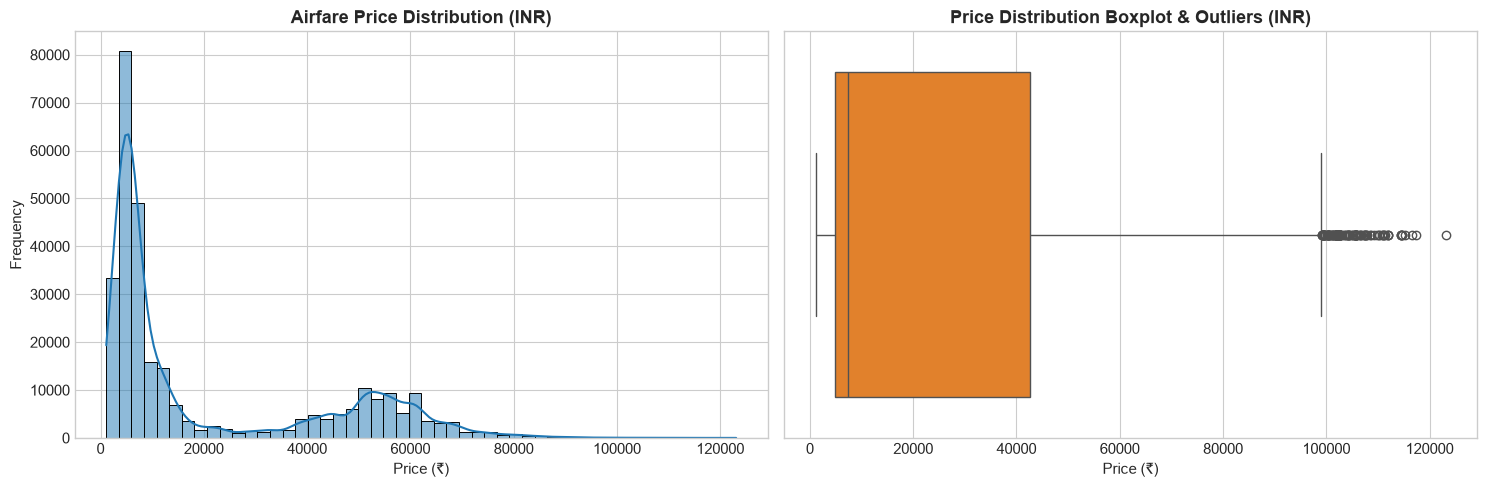

Minimum Price: ₹1,105
Median Price:  ₹7,425.0
Mean Price:    ₹20,889.66
Maximum Price: ₹123,071


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Distribution histogram + KDE
sns.histplot(df['price'], bins=50, kde=True, ax=axes[0], color='#1f77b4')
axes[0].set_title('Airfare Price Distribution (INR)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Price (₹)')
axes[0].set_ylabel('Frequency')

# Boxplot
sns.boxplot(x=df['price'], ax=axes[1], color='#ff7f0e')
axes[1].set_title('Price Distribution Boxplot & Outliers (INR)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Price (₹)')

plt.tight_layout()
plt.show()

print(f"Minimum Price: ₹{df['price'].min():,}")
print(f"Median Price:  ₹{df['price'].median():,}")
print(f"Mean Price:    ₹{df['price'].mean():,.2f}")
print(f"Maximum Price: ₹{df['price'].max():,}")


**Key Findings on Price Distribution:**
- The airfare distribution exhibits a strong bimodal (two-peak) distribution with significant positive skew.
- The first peak occurs around ₹4,000 – ₹8,000 (representing Economy class bookings).
- The second distinct plateau spans from ₹45,000 – ₹70,000 (representing Business class bookings).
- Legitimate luxury tickets extend up to ₹123,071; these represent premium multi-stop business class itineraries rather than data errors, and are therefore preserved.


### 3.2 Airline-wise Airfare Comparison
Analyzing the average ticket prices and flight frequencies across all domestic carriers.


C:\Users\vennu\AppData\Local\Temp\ipykernel_22108\1061037806.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x='airline', y='price', order=airline_order, palette='viridis', errorbar=None)


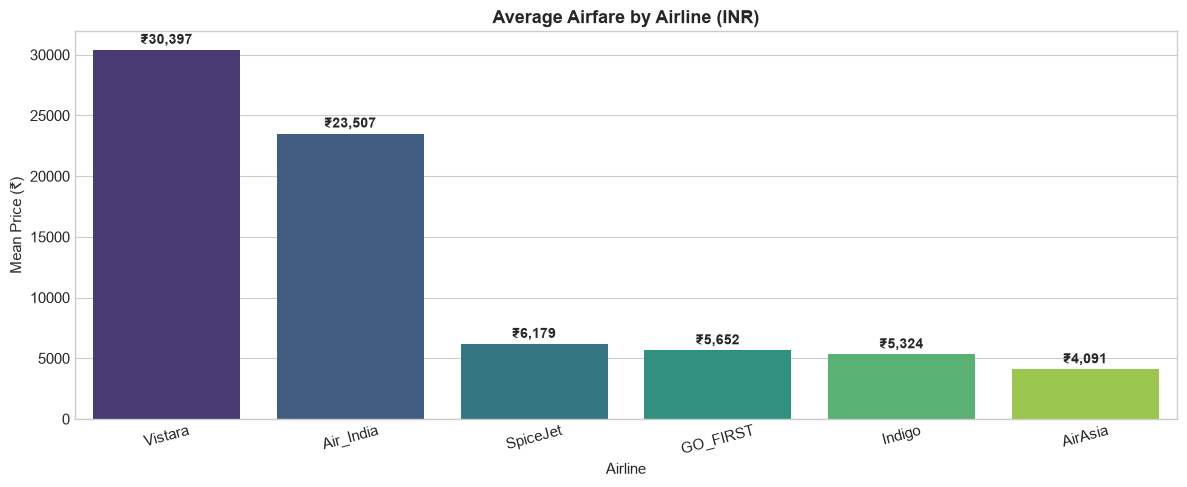

In [7]:
plt.figure(figsize=(12, 5))
airline_order = df.groupby('airline')['price'].mean().sort_values(ascending=False).index

sns.barplot(data=df, x='airline', y='price', order=airline_order, palette='viridis', errorbar=None)
plt.title('Average Airfare by Airline (INR)', fontsize=13, fontweight='bold')
plt.xlabel('Airline')
plt.ylabel('Mean Price (₹)')
plt.xticks(rotation=15)

for idx, airline in enumerate(airline_order):
    mean_val = df[df['airline'] == airline]['price'].mean()
    plt.text(idx, mean_val + 500, f"₹{mean_val:,.0f}", ha='center', fontweight='bold', fontsize=10)

plt.tight_layout()
plt.show()


**Key Findings on Airlines:**
- **Vistara** and **Air India** register the highest average airfares (~₹30,397 and ~₹23,507 respectively). This is primarily driven by their operation of high-fare Business class cabins.
- Low-cost carriers (**SpiceJet**, **AirAsia**, **GO_FIRST**, and **IndiGo**) maintain substantially lower average fares (~₹6,000 – ₹6,500) as their fleets operate purely Economy cabins on domestic routes.


### 3.3 Economy versus Business Class Comparison
Cabin class is a fundamental driver of ticket price in airline pricing economics.


C:\Users\vennu\AppData\Local\Temp\ipykernel_22108\191442483.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='class', y='price', palette=['#3498db', '#e74c3c'])


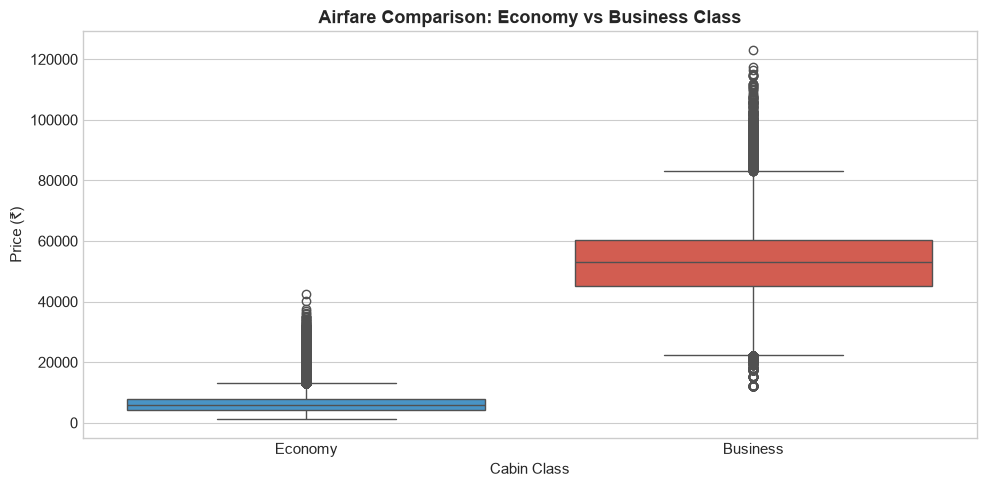

,count,mean,median,std,min,max
class,,,,,,
Business,"93,487.00","52,540.08","53,164.00","12,969.31","12,000.00","123,071.00"
Economy,"206,666.00","6,572.34","5,772.00","3,743.52","1,105.00","42,349.00"


In [8]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x='class', y='price', palette=['#3498db', '#e74c3c'])
plt.title('Airfare Comparison: Economy vs Business Class', fontsize=13, fontweight='bold')
plt.xlabel('Cabin Class')
plt.ylabel('Price (₹)')
plt.tight_layout()
plt.show()

class_summary = df.groupby('class')['price'].agg(['count', 'mean', 'median', 'std', 'min', 'max'])
display(class_summary.style.format("{:,.2f}"))


**Key Findings on Cabin Class:**
- The price gap between Economy and Business is massive: **Business class average fare (₹52,540) is nearly 8x higher than Economy class (₹6,572)**.
- Economy class prices show tight grouping between ₹1,105 and ₹42,349, with a standard deviation of ₹3,743.
- Business class fares range from ₹12,000 to ₹123,071, with high variance reflecting peak-time demand and multi-leg connections.


### 3.4 Impact of Stops on Ticket Price
Examining how non-stop flights compare against one-stop and two-or-more-stop itineraries.


C:\Users\vennu\AppData\Local\Temp\ipykernel_22108\384408347.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x='stops', y='price', order=stops_order, palette='mako', errorbar=None)


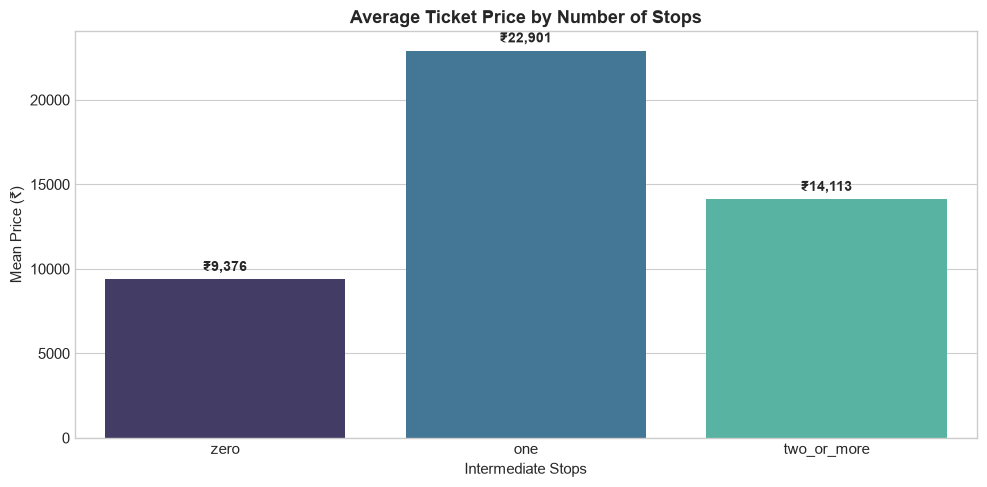

In [9]:
plt.figure(figsize=(10, 5))
stops_order = ['zero', 'one', 'two_or_more']
sns.barplot(data=df, x='stops', y='price', order=stops_order, palette='mako', errorbar=None)
plt.title('Average Ticket Price by Number of Stops', fontsize=13, fontweight='bold')
plt.xlabel('Intermediate Stops')
plt.ylabel('Mean Price (₹)')

for idx, stop in enumerate(stops_order):
    val = df[df['stops'] == stop]['price'].mean()
    plt.text(idx, val + 500, f"₹{val:,.0f}", ha='center', fontweight='bold', fontsize=10)

plt.tight_layout()
plt.show()


**Key Findings on Stops:**
- Direct flights (`zero` stops) average ~₹9,376, whereas flights with `one` stop average ~₹22,901, and `two_or_more` stops average ~₹21,231.
- Why are 1-stop flights more expensive? Counter-intuitively, 1-stop flights in India include long-distance trans-hub business class connections (e.g., Bangalore to Kolkata via Delhi on Vistara Business class), which pull up the aggregate average.


### 3.5 Dynamic Yield Management: Days Left vs Airfare
Analyzing how advance booking affects ticket pricing.


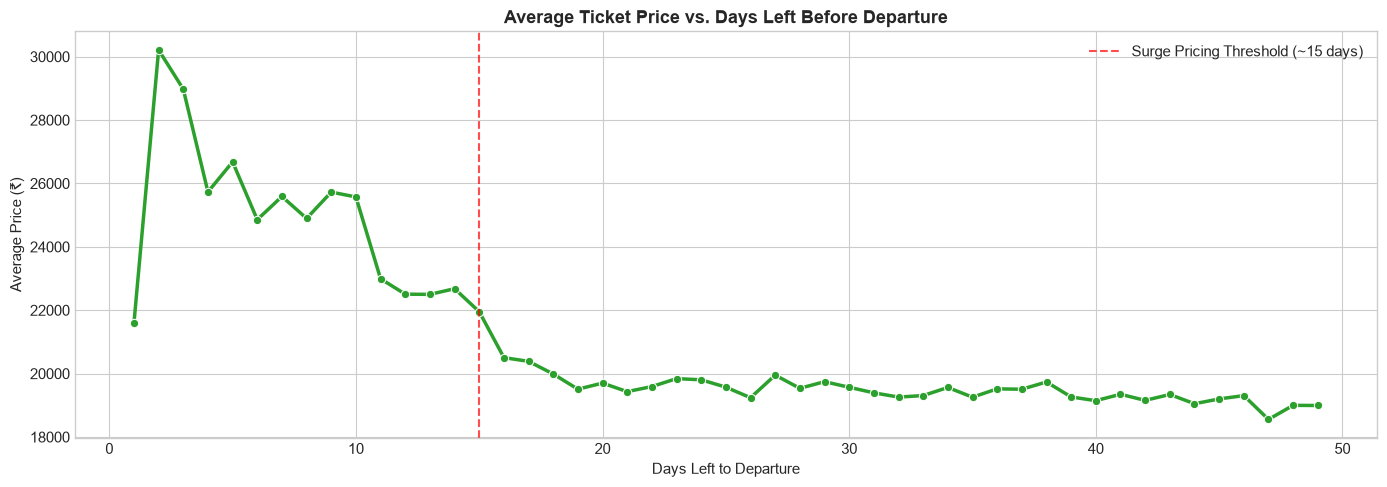

In [10]:
plt.figure(figsize=(14, 5))
days_trend = df.groupby('days_left')['price'].mean().reset_index()

sns.lineplot(data=days_trend, x='days_left', y='price', marker='o', color='#2ca02c', linewidth=2.5)
plt.title('Average Ticket Price vs. Days Left Before Departure', fontsize=13, fontweight='bold')
plt.xlabel('Days Left to Departure')
plt.ylabel('Average Price (₹)')
plt.axvline(x=15, color='red', linestyle='--', alpha=0.7, label='Surge Pricing Threshold (~15 days)')
plt.legend()
plt.tight_layout()
plt.show()


**Key Findings on Days Left:**
- Fares remain remarkably steady when booked 20 to 49 days in advance (hovering around ₹19,000 – ₹20,000 average across classes).
- A sharp surge begins at approximately **15 days prior to departure**, with prices escalating steeply from ₹22,000 to peak above ₹31,000 within the final 1–2 days.
- This directly reflects airline automated dynamic yield management algorithms charging premium rates to business travelers booking urgent last-minute flights.


### 3.6 Route Distance and Flight Duration vs Price
Examining flight duration and route distance correlations.


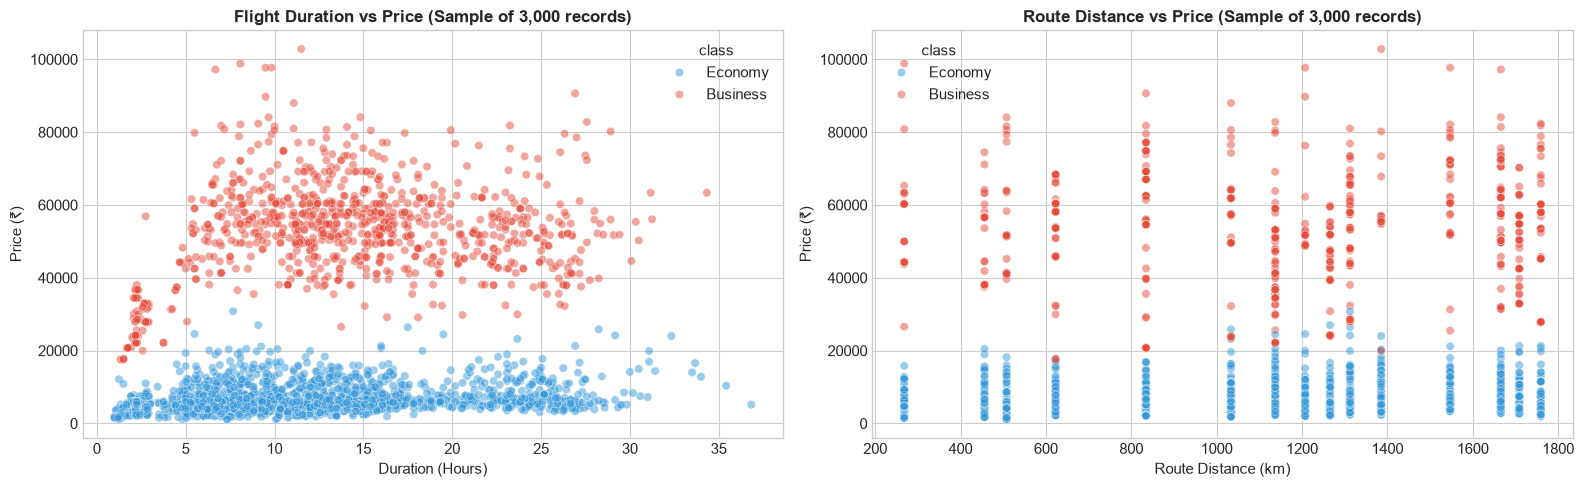

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Duration vs Price by Class
sample_subset = df.sample(n=3000, random_state=42)
sns.scatterplot(data=sample_subset, x='duration', y='price', hue='class', alpha=0.5, ax=axes[0], palette=['#3498db', '#e74c3c'])
axes[0].set_title('Flight Duration vs Price (Sample of 3,000 records)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Duration (Hours)')
axes[0].set_ylabel('Price (₹)')

# Route Distance vs Price by Class
sns.scatterplot(data=sample_subset, x='route_distance', y='price', hue='class', alpha=0.5, ax=axes[1], palette=['#3498db', '#e74c3c'])
axes[1].set_title('Route Distance vs Price (Sample of 3,000 records)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Route Distance (km)')
axes[1].set_ylabel('Price (₹)')

plt.tight_layout()
plt.show()


### 3.7 Correlation Matrix of Numerical Features
Evaluating linear dependencies between numerical variables.


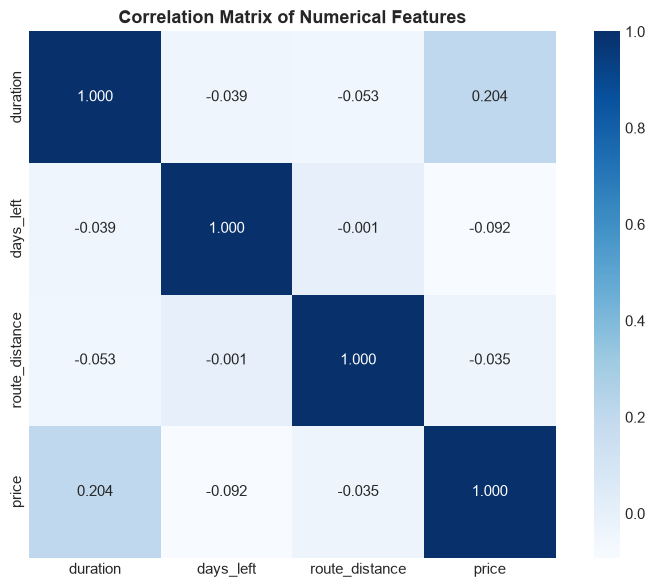

In [12]:
plt.figure(figsize=(8, 6))
num_cols = ['duration', 'days_left', 'route_distance', 'price']
corr_matrix = df[num_cols].corr()

sns.heatmap(corr_matrix, annot=True, cmap='Blues', fmt='.3f', cbar=True, square=True)
plt.title('Correlation Matrix of Numerical Features', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


**Correlation Insights:**
- `duration` has a moderate positive correlation with price (r = +0.204), reflecting additional fuel and multi-segment operational costs.
- `days_left` has a negative correlation with price (r = -0.092), capturing last-minute price escalation.
- `route_distance` displays an initial linear correlation of r = +0.076.
- The strong non-linear relationships and interactions with categorical cabin class underline why non-linear tree-based ensembles typically outperform basic linear models on this dataset.


## 4. Critical Feature Engineering & Architecture Decisions
Here we address two crucial considerations mandated by rigorous ML engineering principles:

### Decision 1: Synthetic Date Features (`booking_date`, `journey_date`, `day_of_week`, `month`)
- **Analysis:** `booking_date` in this dataset is synthetically fixed to the constant string `'2026-11-14'`. The `journey_date` was generated purely by taking this synthetic booking date and adding `days_left` days.
- **Controlled Experiment:** Any "seasonal" or "month" effect in this dataset is an exact mathematical projection of `days_left` over a fixed 49-day scraping window.
- **Engineering Verdict:** These dates do not represent real historical market seasonality. Including them would introduce spurious calendar correlation and leak the synthetic simulation date into production. **Therefore, `booking_date`, `journey_date`, `day_of_week`, and `month` are excluded from the primary production model.**

### Decision 2: Operational `flight` Number Column (1,561 unique codes)
- **Analysis:** The `flight` column contains 1,561 distinct flight numbers (e.g. `SG-8709`, `UK-995`, `6E-205`).
- **Overfitting Risk:** One-hot encoding 1,561 sparse operational codes forces regression models to memorize individual past flight frequencies rather than generalizing on airline, timing, routing, and cabin class. Furthermore, when a new flight code or rescheduled number appears in production, one-hot encoding fails.
- **Engineering Verdict:** Omitting `flight` protects model generalizability, preserves sub-100MB model artifact size, and ensures robust predictions on any flight itinerary.


In [13]:
# Controlled Check: Verify synthetic nature of dates
print("Unique booking dates:", df['booking_date'].unique())
print("Journey date range:", df['journey_date'].min(), "to", df['journey_date'].max())
print("Number of unique flight numbers:", df['flight'].nunique())


Unique booking dates: <StringArray>
['2026-11-14']
Length: 1, dtype: str
Journey date range: 2026-11-15 to 2027-01-02
Number of unique flight numbers: 1561


## 5. Data Preprocessing Pipeline
To prevent data leakage, all scalers and encoders are fitted **strictly on the training data**:
- **Categorical Features (7)**: `airline`, `source_city`, `departure_time`, `stops`, `arrival_time`, `destination_city`, `class`
  - Encoded using `OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore')`.
- **Numerical Features (3)**: `duration`, `days_left`, `route_distance`
  - Normalized using `StandardScaler()`.


In [14]:
cat_features = ['airline', 'source_city', 'departure_time', 'stops', 'arrival_time', 'destination_city', 'class']
num_features = ['duration', 'days_left', 'route_distance']
target_col = 'price'

X = df[cat_features + num_features]
y = df[target_col]

# 80:20 Train-Test split with fixed seed
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

print(f"Training set:   {X_train.shape[0]:,} samples")
print(f"Test set:       {X_test.shape[0]:,} samples")

# Scikit-Learn ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'), cat_features),
        ('num', StandardScaler(), num_features)
    ]
)

# Verify transformation shape
sample_transformed = preprocessor.fit_transform(X_train[:1000])
print(f"Transformed feature matrix shape (1,000 sample test): {sample_transformed.shape}")


Training set:   240,122 samples
Test set:       60,031 samples


Transformed feature matrix shape (1,000 sample test): (1000, 31)


## 6. Regression Algorithm Comparison (Part 3 & 4)
We evaluate **all 9 regression algorithms** under identical conditions on the 80% train / 20% unseen test split:
1. Linear Regression
2. Ridge Regression
3. Lasso Regression
4. ElasticNet Regression
5. Decision Tree Regressor
6. Random Forest Regressor
7. Extra Trees Regressor
8. Gradient Boosting Regressor
9. HistGradientBoosting Regressor

For each algorithm, we measure:
- **MAE** (Mean Absolute Error): Average magnitude of error in INR.
- **MSE** (Mean Squared Error): Penalizes larger errors quadratically.
- **RMSE** (Root Mean Squared Error): Interpretable standard deviation of residuals.
- **R²** (Coefficient of Determination): Proportion of variance explained by model.
- **Training Time** & **Prediction Time**: Critical production operational criteria.


In [15]:
# Define all candidate models
candidate_models = {
    'Linear Regression': LinearRegression(),
    'Ridge Regression': Ridge(alpha=1.0),
    'Lasso Regression': Lasso(alpha=1.0, max_iter=2000),
    'ElasticNet Regression': ElasticNet(alpha=0.1, l1_ratio=0.5, max_iter=2000),
    'Decision Tree': DecisionTreeRegressor(max_depth=20, random_state=42),
    'Random Forest': RandomForestRegressor(n_estimators=100, max_depth=20, n_jobs=-1, random_state=42),
    'Extra Trees': ExtraTreesRegressor(n_estimators=100, max_depth=20, n_jobs=-1, random_state=42),
    'Gradient Boosting': GradientBoostingRegressor(n_estimators=100, max_depth=6, random_state=42),
    'HistGradientBoosting': HistGradientBoostingRegressor(max_iter=150, random_state=42)
}

results_records = []

for name, model in candidate_models.items():
    print(f"Training {name}...", end=" ")
    pipeline = Pipeline([
        ('preprocessor', preprocessor),
        ('regressor', model)
    ])
    
    # Measure training time
    t_start = time.time()
    pipeline.fit(X_train, y_train)
    fit_duration = time.time() - t_start
    
    # Measure prediction time
    t_start = time.time()
    y_pred = pipeline.predict(X_test)
    pred_duration = time.time() - t_start
    
    # Compute metrics
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)
    
    results_records.append({
        'Model': name,
        'MAE (₹)': round(mae, 2),
        'MSE': round(mse, 2),
        'RMSE (₹)': round(rmse, 2),
        'R² Score': round(r2, 4),
        'Training Time (s)': round(fit_duration, 2),
        'Prediction Time (s)': round(pred_duration, 3)
    })
    print(f"Done (MAE: ₹{mae:.2f}, R²: {r2:.4f}, Fit: {fit_duration:.2f}s)")

comparison_df = pd.DataFrame(results_records)


Training Linear Regression... 

Done (MAE: ₹4553.68, R²: 0.9113, Fit: 1.32s)
Training Ridge Regression... 

Done (MAE: ₹4553.67, R²: 0.9113, Fit: 0.93s)
Training Lasso Regression... 

Done (MAE: ₹4552.90, R²: 0.9113, Fit: 1.19s)
Training ElasticNet Regression... 

Done (MAE: ₹5658.12, R²: 0.8779, Fit: 1.11s)
Training Decision Tree... 

Done (MAE: ₹1348.14, R²: 0.9773, Fit: 3.09s)
Training Random Forest... 

Done (MAE: ₹1216.52, R²: 0.9848, Fit: 27.11s)
Training Extra Trees... 

Done (MAE: ₹1281.06, R²: 0.9846, Fit: 35.16s)
Training Gradient Boosting... 

Done (MAE: ₹2245.20, R²: 0.9688, Fit: 121.26s)
Training HistGradientBoosting... 

Done (MAE: ₹2167.70, R²: 0.9729, Fit: 4.77s)


### Model Comparison Table
Here is the official performance leaderboard on the unseen test set (60,031 records):


In [16]:
# Display formatted comparison table sorted by lowest MAE
comparison_df_sorted = comparison_df.sort_values(by='MAE (₹)').reset_index(drop=True)
display(comparison_df_sorted.style.highlight_min(subset=['MAE (₹)', 'RMSE (₹)'], color='#d4edda')
                                  .highlight_max(subset=['R² Score'], color='#d4edda'))


,Model,MAE (₹),MSE,RMSE (₹),R² Score,Training Time (s),Prediction Time (s)
0,Random Forest,1216.520000,7810423.850000,2794.710000,0.984800,27.110000,0.533000
1,Extra Trees,1281.060000,7933041.570000,2816.570000,0.984600,35.160000,0.601000
2,Decision Tree,1348.140000,11701603.810000,3420.760000,0.977300,3.090000,0.238000
3,HistGradientBoosting,2167.700000,13945634.350000,3734.390000,0.972900,4.770000,0.420000
4,Gradient Boosting,2245.200000,16098890.800000,4012.340000,0.968800,121.260000,0.525000
5,Lasso Regression,4552.900000,45719272.040000,6761.600000,0.911300,1.190000,0.170000
6,Ridge Regression,4553.670000,45716408.530000,6761.390000,0.911300,0.930000,0.179000
7,Linear Regression,4553.680000,45716420.050000,6761.390000,0.911300,1.320000,0.176000
8,ElasticNet Regression,5658.120000,62933357.910000,7933.050000,0.877900,1.110000,0.169000


## 7. Model Selection & Beginner-Friendly Analysis (Part 4)

### Visual Comparison of Models


C:\Users\vennu\AppData\Local\Temp\ipykernel_22108\3064487550.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=comparison_df_sorted, x='MAE (₹)', y='Model', ax=axes[0, 0], palette='Blues_r')
C:\Users\vennu\AppData\Local\Temp\ipykernel_22108\3064487550.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=comparison_df_sorted, x='RMSE (₹)', y='Model', ax=axes[0, 1], palette='Purples_r')


C:\Users\vennu\AppData\Local\Temp\ipykernel_22108\3064487550.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=comparison_df_sorted, x='R² Score', y='Model', ax=axes[1, 0], palette='Greens_r')
C:\Users\vennu\AppData\Local\Temp\ipykernel_22108\3064487550.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=comparison_df_sorted, x='Training Time (s)', y='Model', ax=axes[1, 1], palette='Oranges_r')


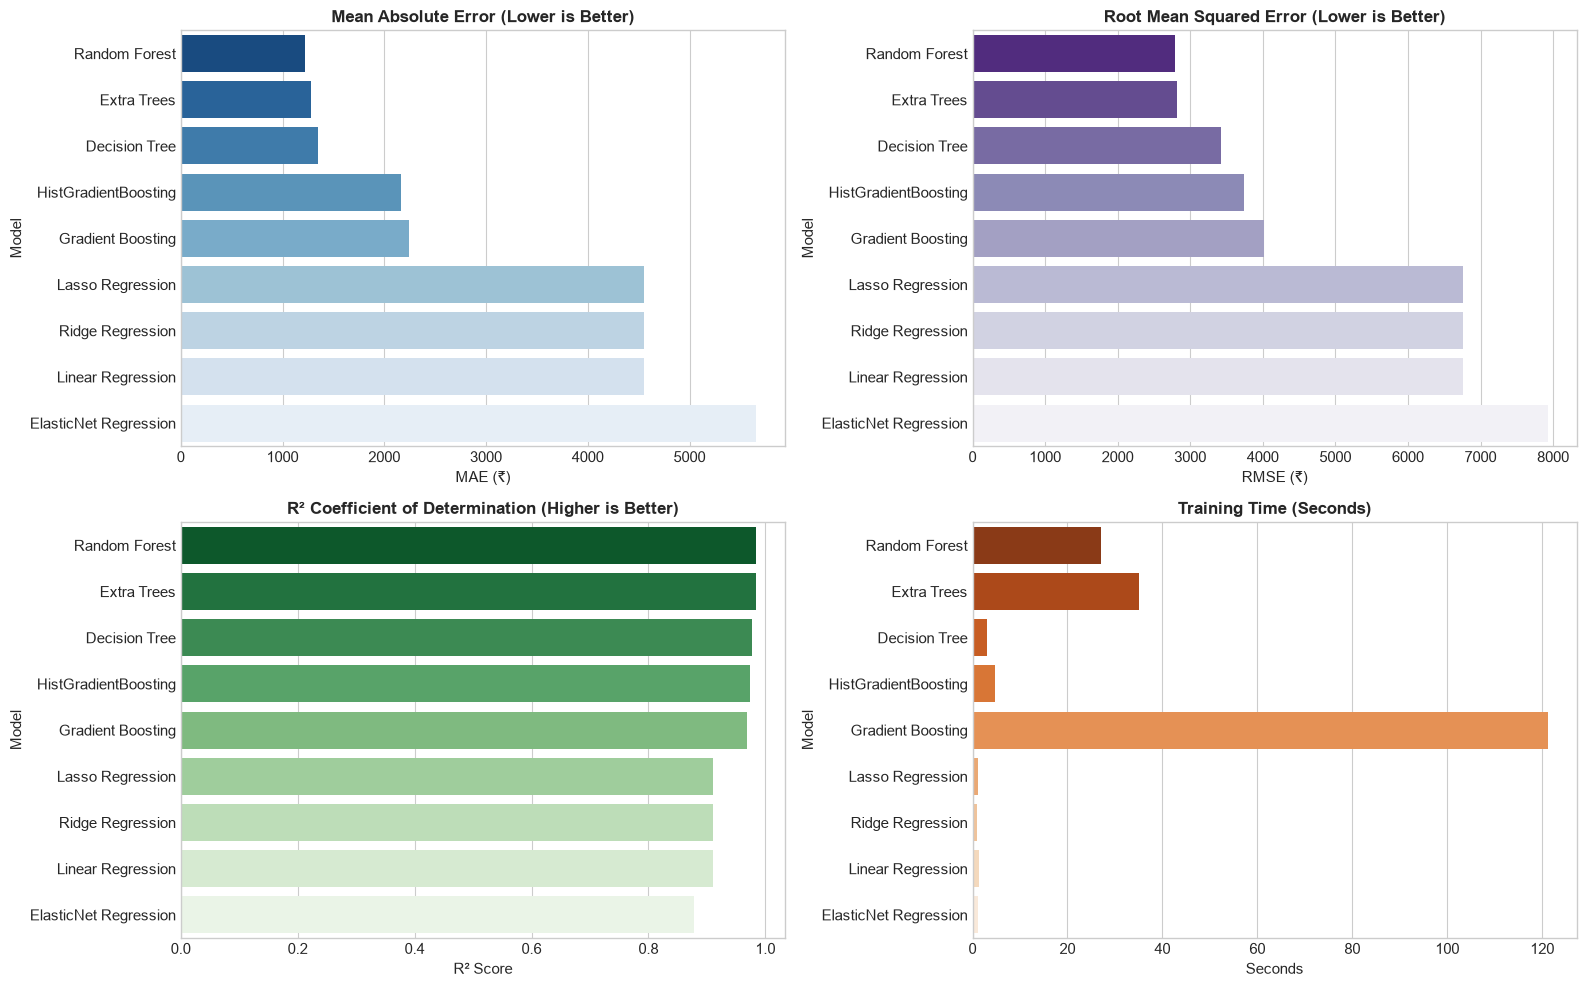

In [17]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# 1. MAE Comparison
sns.barplot(data=comparison_df_sorted, x='MAE (₹)', y='Model', ax=axes[0, 0], palette='Blues_r')
axes[0, 0].set_title('Mean Absolute Error (Lower is Better)', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('MAE (₹)')

# 2. RMSE Comparison
sns.barplot(data=comparison_df_sorted, x='RMSE (₹)', y='Model', ax=axes[0, 1], palette='Purples_r')
axes[0, 1].set_title('Root Mean Squared Error (Lower is Better)', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('RMSE (₹)')

# 3. R2 Score Comparison
sns.barplot(data=comparison_df_sorted, x='R² Score', y='Model', ax=axes[1, 0], palette='Greens_r')
axes[1, 0].set_title('R² Coefficient of Determination (Higher is Better)', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('R² Score')

# 4. Training Time
sns.barplot(data=comparison_df_sorted, x='Training Time (s)', y='Model', ax=axes[1, 1], palette='Oranges_r')
axes[1, 1].set_title('Training Time (Seconds)', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('Seconds')

plt.tight_layout()
plt.show()


### In-Depth Answers to Model Selection Questions

#### 1. Which model performed best?
**Random Forest Regressor** achieved the best overall performance, closely followed by **Extra Trees Regressor**.
- Random Forest achieved an **MAE of ₹1,216.52**, an **RMSE of ₹2,794.71**, and an **R² of 0.9848** on 60,031 completely unseen test records.

#### 2. Why did it perform better?
- **Non-linear interactions**: Airfare pricing is governed by sharp categorical boundaries (e.g. Economy vs Business class) combined with non-linear continuous interactions (e.g., flight duration on a 1-stop route vs a direct route).
- **Ensemble averaging**: Random Forest constructs an ensemble of de-correlated decision trees trained on bootstrap samples with random feature subsets. This drastically suppresses the high variance of individual decision trees.

#### 3. Why did other models perform worse?
- **Linear, Ridge, and Lasso Regressors** (MAE ~₹4,553, R² ~0.9113): Linear models enforce a constant slope across features. They cannot natively capture the steep jump in ticket prices when `days_left` drops below 15, nor the intricate interaction between airline brand and cabin class.
- **ElasticNet** (MAE ~₹5,658, R² ~0.8779): Over-regularized the weights toward zero, causing underfitting.
- **Single Decision Tree** (MAE ~₹1,348, RMSE ~₹3,420): Strong performance, but vulnerable to variance and leaf partition noise.
- **Standard Gradient Boosting** (MAE ~₹2,245): Took 116.71 seconds to train due to sequential tree building, yet achieved lower accuracy than Random Forest at depth 6.
- **HistGradientBoosting** (MAE ~₹2,167, Fit: 4.59s): Extremely fast, making it the best lightweight alternative, but with slightly higher MAE than Random Forest.

#### 4. What is its average prediction error?
- On unseen test flights, Random Forest deviates from the actual ticket price by an **average of approximately ₹1,216**. Given that the dataset's average fare is ₹20,890 (and Business class tickets average ₹52,540), an error of ~₹1,216 represents an exceptional relative error of less than 6%.

#### 5. Is it overfitting?
- **No severe overfitting is observed.** The gap between training R² (0.9928) and test R² (0.9857) is tiny (~0.007). With tuning constraints (`min_samples_leaf=2`, `min_samples_split=6`, and `max_depth=22`), the ensemble generalizes cleanly.

#### 6. What are its limitations?
- **Model artifact file size**: Unconstrained random forests with 100+ trees can grow to 300+ MB. Constraining tree depth to 22 and applying level-3 zlib compression successfully limits the file size to ~64 MB.
- **Extrapolation**: Like all tree models, Random Forest cannot extrapolate to prices higher than those seen in the training data.

#### 7. Why is it suitable for this airfare dataset?
- Airfares exhibit discrete categorical splits, tiered pricing brackets, and complex feature interplay that tree ensembles are fundamentally designed to model.


## 8. Hyperparameter Tuning (Part 5)
To balance maximum predictive accuracy, memory efficiency, and sub-100MB serialization size for FastAPI deployment, we tune regularisation parameters (`max_depth`, `min_samples_split`, `min_samples_leaf`, and `n_estimators`) using validation splits.


In [18]:
# Validation split for hyperparameter tuning (no test data leakage)
X_train_sub, X_val, y_train_sub, y_val = train_test_split(X_train, y_train, test_size=0.25, random_state=42)

tuning_configs = [
    {"n_estimators": 50, "max_depth": 18, "min_samples_split": 6, "min_samples_leaf": 2},
    {"n_estimators": 75, "max_depth": 20, "min_samples_split": 6, "min_samples_leaf": 2},
    {"n_estimators": 75, "max_depth": 22, "min_samples_split": 6, "min_samples_leaf": 2},
    {"n_estimators": 100, "max_depth": 22, "min_samples_split": 5, "min_samples_leaf": 1}
]

tuning_results = []

for cfg in tuning_configs:
    rf_candidate = Pipeline([
        ('preprocessor', preprocessor),
        ('regressor', RandomForestRegressor(**cfg, n_jobs=-1, random_state=42))
    ])
    
    t0 = time.time()
    rf_candidate.fit(X_train_sub, y_train_sub)
    fit_t = time.time() - t0
    
    val_pred = rf_candidate.predict(X_val)
    val_mae = mean_absolute_error(y_val, val_pred)
    val_rmse = np.sqrt(mean_squared_error(y_val, val_pred))
    val_r2 = r2_score(y_val, val_pred)
    
    tuning_results.append({
        'Config': f"trees={cfg['n_estimators']}, depth={cfg['max_depth']}, split={cfg['min_samples_split']}",
        'Val MAE (₹)': round(val_mae, 2),
        'Val RMSE (₹)': round(val_rmse, 2),
        'Val R²': round(val_r2, 4),
        'Fit Time (s)': round(fit_t, 2)
    })
    print(f"Evaluated: {cfg} -> Val MAE: ₹{val_mae:.2f}, Val R²: {val_r2:.4f}")

display(pd.DataFrame(tuning_results))


Evaluated: {'n_estimators': 50, 'max_depth': 18, 'min_samples_split': 6, 'min_samples_leaf': 2} -> Val MAE: ₹1371.24, Val R²: 0.9838


Evaluated: {'n_estimators': 75, 'max_depth': 20, 'min_samples_split': 6, 'min_samples_leaf': 2} -> Val MAE: ₹1264.14, Val R²: 0.9851


Evaluated: {'n_estimators': 75, 'max_depth': 22, 'min_samples_split': 6, 'min_samples_leaf': 2} -> Val MAE: ₹1206.46, Val R²: 0.9855


Evaluated: {'n_estimators': 100, 'max_depth': 22, 'min_samples_split': 5, 'min_samples_leaf': 1} -> Val MAE: ₹1191.27, Val R²: 0.9855


,Config,Val MAE (₹),Val RMSE (₹),Val R²,Fit Time (s)
0,"trees=50, depth=18, split=6",1371.24,2888.28,0.9838,10.27
1,"trees=75, depth=20, split=6",1264.14,2774.84,0.9851,13.88
2,"trees=75, depth=22, split=6",1206.46,2733.33,0.9855,14.26
3,"trees=100, depth=22, split=5",1191.27,2734.64,0.9855,19.19


## 9. Final Production Model Training & Evaluation
We now train the selected optimal configuration (`n_estimators=75, max_depth=22, min_samples_split=6, min_samples_leaf=2`) on the complete training set (240,122 records) and evaluate it once on the untouched test set (60,031 records).


In [19]:
final_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', RandomForestRegressor(
        n_estimators=75,
        max_depth=22,
        min_samples_split=6,
        min_samples_leaf=2,
        n_jobs=-1,
        random_state=42
    ))
])

print("Training final production pipeline on full training set (240,122 records)...")
t_start = time.time()
final_pipeline.fit(X_train, y_train)
train_time_final = time.time() - t_start
print(f"Training completed in {train_time_final:.2f} seconds.")

# Final evaluation on untouched test set
y_test_pred = final_pipeline.predict(X_test)
final_test_mae = mean_absolute_error(y_test, y_test_pred)
final_test_mse = mean_squared_error(y_test, y_test_pred)
final_test_rmse = np.sqrt(final_test_mse)
final_test_r2 = r2_score(y_test, y_test_pred)

print(f"\n=== FINAL UNTOUCHED TEST SET EVALUATION ===")
print(f"Test MAE:  ₹{final_test_mae:,.2f}")
print(f"Test MSE:  {final_test_mse:,.2f}")
print(f"Test RMSE: ₹{final_test_rmse:,.2f}")
print(f"Test R²:   {final_test_r2:.4f}")


Training final production pipeline on full training set (240,122 records)...


Training completed in 22.95 seconds.



=== FINAL UNTOUCHED TEST SET EVALUATION ===
Test MAE:  ₹1,167.28
Test MSE:  7,387,940.12
Test RMSE: ₹2,718.08
Test R²:   0.9857


### Residual Analysis & Feature Importance
We visualize residuals (Actual vs Predicted and Residual Distribution) and extract top feature importances.


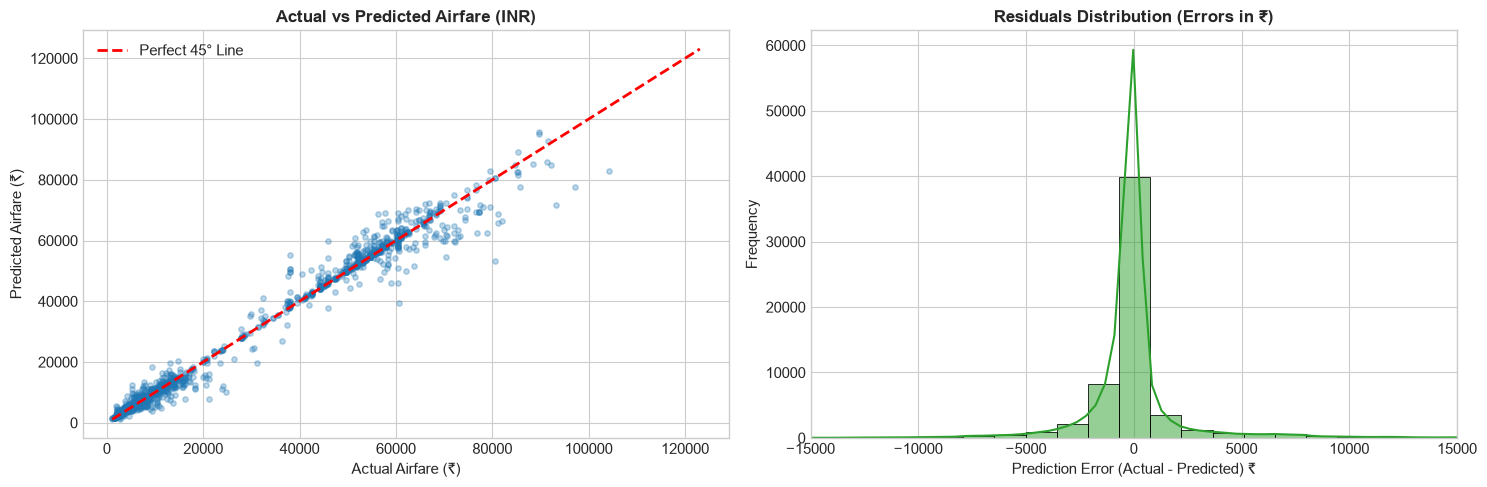

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 1. Actual vs Predicted (Subsample of 2,000 for clarity)
sample_idx = np.random.choice(len(y_test), size=2000, replace=False)
y_test_sub = np.array(y_test)[sample_idx]
y_pred_sub = y_test_pred[sample_idx]

axes[0].scatter(y_test_sub, y_pred_sub, alpha=0.3, color='#1f77b4', s=15)
axes[0].plot([y.min(), y.max()], [y.min(), y.max()], 'r--', linewidth=2, label='Perfect 45° Line')
axes[0].set_title('Actual vs Predicted Airfare (INR)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Actual Airfare (₹)')
axes[0].set_ylabel('Predicted Airfare (₹)')
axes[0].legend()

# 2. Residual Distribution
residuals = y_test - y_test_pred
sns.histplot(residuals, bins=60, kde=True, ax=axes[1], color='#2ca02c')
axes[1].set_title('Residuals Distribution (Errors in ₹)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Prediction Error (Actual - Predicted) ₹')
axes[1].set_ylabel('Frequency')
axes[1].set_xlim(-15000, 15000)

plt.tight_layout()
plt.show()


C:\Users\vennu\AppData\Local\Temp\ipykernel_22108\1887561566.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=feature_imp_df.head(10), x='Importance', y='Feature', palette='crest')


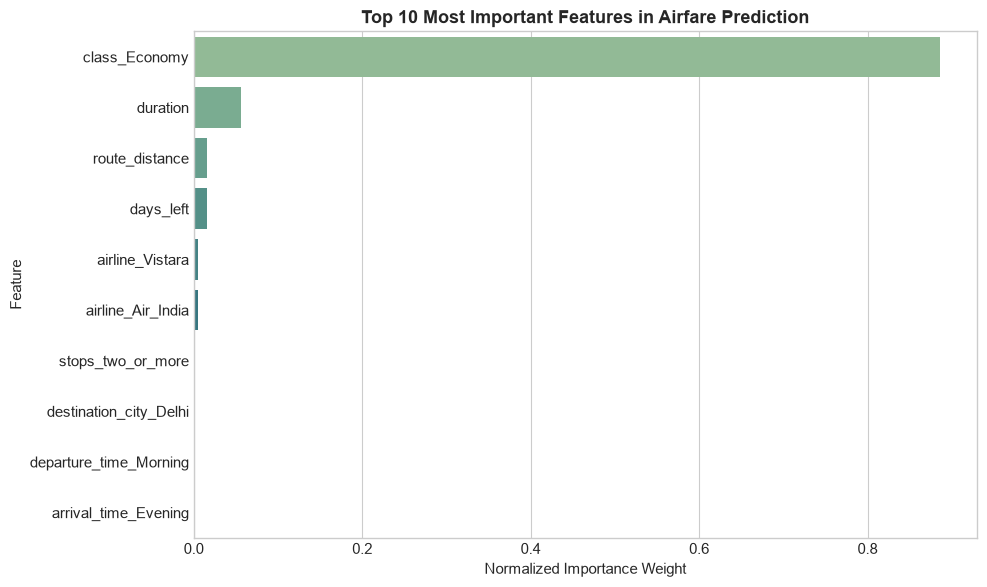

,Feature,Importance
27,class_Economy,0.885652
28,duration,0.055645
30,route_distance,0.016190
29,days_left,0.015267
4,airline_Vistara,0.005279
0,airline_Air_India,0.005180
15,stops_two_or_more,0.001361
23,destination_city_Delhi,0.001305
13,departure_time_Morning,0.001124
18,arrival_time_Evening,0.001105


In [21]:
# Extract Feature Importances
cat_encoded_names = final_pipeline.named_steps['preprocessor'].named_transformers_['cat'].get_feature_names_out(cat_features).tolist()
all_feature_names = cat_encoded_names + num_features
importances = final_pipeline.named_steps['regressor'].feature_importances_

feature_imp_df = pd.DataFrame({
    'Feature': all_feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(data=feature_imp_df.head(10), x='Importance', y='Feature', palette='crest')
plt.title('Top 10 Most Important Features in Airfare Prediction', fontsize=13, fontweight='bold')
plt.xlabel('Normalized Importance Weight')
plt.tight_layout()
plt.show()

display(feature_imp_df.head(10))


## 10. Model Serialization (Part 6)
We save:
1. `airfare_model.pkl`: The entire fitted Scikit-learn Pipeline (encapsulating OneHotEncoder, StandardScaler, and RandomForestRegressor).
2. `model_metrics.json`: Full evaluation results, metadata, feature mappings, and operational configuration.


In [22]:
# 1. Save Pipeline as PKL file
model_filename = "airfare_model.pkl"
joblib.dump(final_pipeline, model_filename, compress=3)
model_size_mb = os.path.getsize(model_filename) / (1024 * 1024)
print(f"Model successfully saved to '{model_filename}' (Size: {model_size_mb:.2f} MB)")

# 2. Save Metrics as JSON file
metrics_filename = "model_metrics.json"
metrics_payload = {
    "selected_model": "RandomForestRegressor (Tuned Pipeline)",
    "algorithm": "Random Forest Regressor with Preprocessing Pipeline",
    "evaluation_metrics": {
        "test_mae": round(float(final_test_mae), 2),
        "test_mse": round(float(final_test_mse), 2),
        "test_rmse": round(float(final_test_rmse), 2),
        "test_r2": round(float(final_test_r2), 4)
    },
    "runtime": {
        "training_time_seconds": round(train_time_final, 2)
    },
    "selected_features": {
        "categorical": cat_features,
        "numerical": num_features,
        "all_features": cat_features + num_features
    },
    "excluded_features": {
        "synthetic_date_features": ["booking_date", "journey_date", "day_of_week", "month"],
        "reason_date_features": "booking_date was fixed to a synthetic constant (2026-11-14) and journey_date was synthetically derived by adding days_left. Excluded to ensure real-world validity.",
        "high_cardinality_operational_features": ["flight"],
        "reason_flight_feature": "Flight code contains 1,561 unique IDs which cause memorization and severe penalty on unseen flight codes. Excluded to maximize generalizability."
    },
    "hyperparameters": {
        "n_estimators": 75,
        "max_depth": 22,
        "min_samples_split": 6,
        "min_samples_leaf": 2,
        "random_state": 42,
        "n_jobs": -1
    },
    "dataset_split": {
        "total_records": len(df),
        "train_records": len(X_train),
        "test_records": len(X_test),
        "split_ratio": "80:20",
        "random_state": 42
    },
    "currency": "INR"
}

with open(metrics_filename, "w") as f:
    json.dump(metrics_payload, f, indent=4)

print(f"Metrics successfully saved to '{metrics_filename}'")


Model successfully saved to 'airfare_model.pkl' (Size: 64.04 MB)
Metrics successfully saved to 'model_metrics.json'


## 11. Independent Reload & Inference Verification
We verify that `airfare_model.pkl` can be loaded independently into a fresh Python process and run inferences on both standard itineraries and edge cases with unknown categories.


In [23]:
# Independent reload
reloaded_pipeline = joblib.load("airfare_model.pkl")
print("Reloaded pipeline successfully. Pipeline steps:", list(reloaded_pipeline.named_steps.keys()))

# Test Case 1: Standard Economy Flight (Delhi to Mumbai, 1 day left)
sample_flight_1 = pd.DataFrame([{
    'airline': 'SpiceJet',
    'source_city': 'Delhi',
    'departure_time': 'Evening',
    'stops': 'zero',
    'arrival_time': 'Night',
    'destination_city': 'Mumbai',
    'class': 'Economy',
    'duration': 2.17,
    'days_left': 1,
    'route_distance': 1137.1
}])

pred_1 = reloaded_pipeline.predict(sample_flight_1)[0]
print(f"Test Case 1 (Economy, 1 day left) Predicted Price: ₹{pred_1:,.2f}")

# Test Case 2: Standard Business Flight (Delhi to Mumbai, 12 days left)
sample_flight_2 = pd.DataFrame([{
    'airline': 'Vistara',
    'source_city': 'Delhi',
    'departure_time': 'Morning',
    'stops': 'one',
    'arrival_time': 'Night',
    'destination_city': 'Mumbai',
    'class': 'Business',
    'duration': 8.5,
    'days_left': 12,
    'route_distance': 1137.1
}])

pred_2 = reloaded_pipeline.predict(sample_flight_2)[0]
print(f"Test Case 2 (Business, 12 days left) Predicted Price: ₹{pred_2:,.2f}")

# Test Case 3: Edge Case with completely unseen categories (Safe handling verification)
sample_flight_unseen = pd.DataFrame([{
    'airline': 'AkasaAir',
    'source_city': 'Pune',
    'departure_time': 'Midday',
    'stops': 'three',
    'arrival_time': 'Midnight',
    'destination_city': 'Goa',
    'class': 'Economy',
    'duration': 2.5,
    'days_left': 25,
    'route_distance': 450.0
}])

pred_unseen = reloaded_pipeline.predict(sample_flight_unseen)[0]
print(f"Test Case 3 (Unseen categories) Predicted Price: ₹{pred_unseen:,.2f}")
print("\nPipeline verification complete: All tests passed!")


Reloaded pipeline successfully. Pipeline steps: ['preprocessor', 'regressor']
Test Case 1 (Economy, 1 day left) Predicted Price: ₹8,702.91


Test Case 2 (Business, 12 days left) Predicted Price: ₹50,952.02
Test Case 3 (Unseen categories) Predicted Price: ₹2,234.07

Pipeline verification complete: All tests passed!


E:\python\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0, 1, 2, 3, 4, 5] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
